# B-6511502A — como está o modelo de anomalia do pacote de deploy

Roda o bundle `model_2022-05-17_2023-05-17_VAE` do `deploy_v2/Transpetro/B-6511502A` com o módulo
compartilhado `simpred_inference.py`, os mesmos 4 passos do `b6511502a_exemplo.py`. **Nada é treinado aqui.**

- Falha: **15/05/2023**, quebra das lâminas do acoplamento (mesmo modo do B-8802B em 2022).
- Dado disponível: 17/05/2022 a 17/05/2023. **Não temos dado depois disso**, então este notebook mostra o
  modelo só no ano em que ele foi treinado; o comportamento em 2024–2026 ainda não foi visto.
- Aqui é só o **modelo de anomalia** (alerta para a operação). Este equipamento ainda não tem o monitor de
  mudança de conceito (KS / resíduo).

In [1]:
from pathlib import Path
import sys, json, shutil, tempfile
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SAVE_PLOTS = False

ROOT = Path.cwd()
while not (ROOT / "deploy_v2").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DEPLOY = ROOT / "deploy_v2" / "Transpetro"
EQUIP = "B-6511502A"
BUNDLE = DEPLOY / EQUIP / "modelos" / "model_2022-05-17_2023-05-17_VAE"
DADOS = DEPLOY / EQUIP / "dados"
sys.path.insert(0, str(DEPLOY))
import simpred_inference as si

FALHA = pd.Timestamp("2023-05-15")

## Os 4 passos do script de exemplo

In [2]:
raw = si.carregar_dados(si.achar_csv(DADOS, "data_2022-05-17_2023-05-17_raw.csv"))
proc = si.preprocessar(BUNDLE, raw)
model = si.carregar_modelo(BUNDLE)
alarm = json.loads((BUNDLE / "alarm.json").read_text())
THR = float(alarm["threshold"])
print(f"{len(raw):,} linhas brutas ({raw.index.min():%d/%m/%Y} a {raw.index.max():%d/%m/%Y}) -> "
      f"{len(proc):,} instantes com a bomba operando, {proc.shape[1]} sensores")
print(f"limiar de alarme: {THR:.3f}   persistência: {alarm['debounce_min']} de {alarm['debounce_window']} pontos de 5 min")
print(f"último instante operando: {proc.index.max()}  ({(FALHA - proc.index.max()).total_seconds()/3600:.0f} h antes da falha registrada)")

105,120 linhas brutas (17/05/2022 a 17/05/2023) -> 36,387 instantes com a bomba operando, 14 sensores
limiar de alarme: 0.757   persistência: 6 de 6 pontos de 5 min
último instante operando: 2023-05-13 14:35:00  (33 h antes da falha registrada)


## Regra de alerta: a deste bundle e a do B-8802B-2025

O `simpred_inference.py` é o mesmo para todos; a regra de cada equipamento está no `alarm.json` do bundle.

| | Este bundle (B-6511502A, jul/2026) | B-8802B-2025 (regra atual) |
|---|---|---|
| Alarme | 6 pontos seguidos acima do limiar (30 min) | 15 de 20 pontos de 5 min acima do limiar, contados no tempo |
| Alerta para a operação | igual ao alarme | só se o alarme durar **1 h ou mais** |

Abaixo, o mesmo modelo com as duas regras (a segunda numa cópia temporária do bundle; nada é alterado).

In [3]:
tmp = Path(tempfile.mkdtemp()) / "bundle"
shutil.copytree(BUNDLE, tmp)
a2 = dict(alarm, debounce_window=20, debounce_min=15, persistence_mode="time",
          persistence_step="5min", min_alert_hours=1.0)
(tmp / "alarm.json").write_text(json.dumps(a2))

regras = {"bundle atual (6 seguidos)": si.prever(BUNDLE, model, proc),
          "regra B-8802B-2025 (15 de 20, alerta ≥1 h)": si.prever(tmp, model, proc, raw)}

def episodios(flag):
    x = flag[flag]
    if x.empty:
        return []
    bloco = (x.index.to_series().diff() > pd.Timedelta("1h")).cumsum()
    return [(e.index.min(), e.index.max()) for _, e in x.groupby(bloco)]

linhas = []
for nome, r in regras.items():
    for ini, fim in episodios(r["alerta"]):
        linhas.append({"regra": nome, "início": ini, "fim": fim,
                       "tipo": "antes da falha" if FALHA - ini < pd.Timedelta(days=7) else "falso (período normal)",
                       "horas antes da falha": round((FALHA - ini).total_seconds() / 3600)})
pd.DataFrame(linhas)

,regra,início,fim,tipo,horas antes da falha
0,bundle atual (6 seguidos),2022-06-24 19:40:00,2022-06-24 19:45:00,falso (período normal),7780
1,bundle atual (6 seguidos),2022-07-22 16:15:00,2022-07-22 17:00:00,falso (período normal),7112
2,bundle atual (6 seguidos),2023-05-10 07:50:00,2023-05-10 08:15:00,antes da falha,112
3,bundle atual (6 seguidos),2023-05-12 22:10:00,2023-05-13 14:35:00,antes da falha,50
4,"regra B-8802B-2025 (15 de 20, alerta ≥1 h)",2023-05-12 23:35:00,2023-05-13 14:35:00,antes da falha,48


In [4]:
res = regras["bundle atual (6 seguidos)"]
rel = res["reconstruction_error"] / THR
print("maior erro do dia / limiar, maio de 2023 (vazio = bomba parada):")
print(rel.resample("D").max()["2023-05-01":].round(2).to_string())
print(f"\nperíodo normal (até 30/04/2023): {(rel[:'2023-04-30'].resample('D').max() > 1).sum()} dias com algum ponto acima do limiar")

maior erro do dia / limiar, maio de 2023 (vazio = bomba parada):
Timestamp
2023-05-01      NaN
2023-05-02      NaN
2023-05-03      NaN
2023-05-04     0.55
2023-05-05     0.86
2023-05-06     0.74
2023-05-07      NaN
2023-05-08     0.42
2023-05-09     0.96
2023-05-10     1.59
2023-05-11     5.89
2023-05-12     4.87
2023-05-13    11.09
Freq: D

período normal (até 30/04/2023): 35 dias com algum ponto acima do limiar


## Série temporal com os pontos que o modelo marcou

Com a regra de 1 h (a que vamos adotar):
- **bolinhas vermelhas**: instantes em **alarme** do modelo (15 de 20 pontos acima do limiar);
- **faixa vermelha**: trecho em que o alarme já dura 1 h ou mais e vira **alerta para a operação**.

Nos sensores, a linha só aparece com a bomba operando (corrente > 60 A).

O alarme é decidido olhando os últimos 100 min (15 de 20 pontos). Por isso pode cair uma bolinha vermelha num
ponto que, sozinho, está abaixo do limiar: ele está em alarme porque a maioria dos pontos anteriores estava acima.
Em 22/07/2022, as duas vibrações do mancal LA do motor foram a zero com a bomba operando (falha de leitura): o
modelo marca alarme, mas dura menos de 1 h e não vira alerta.

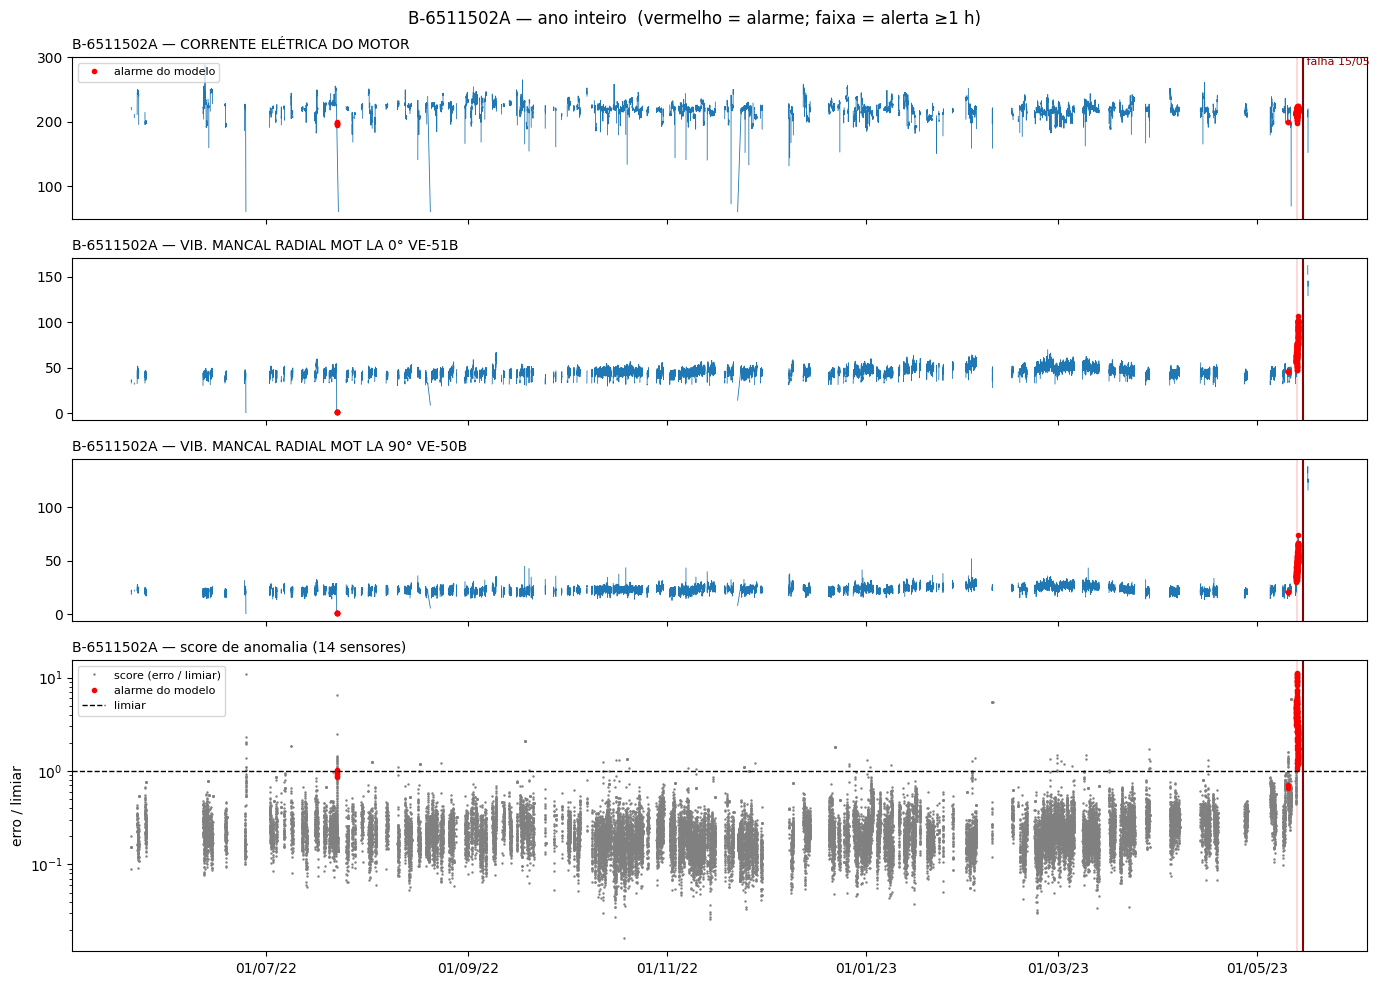

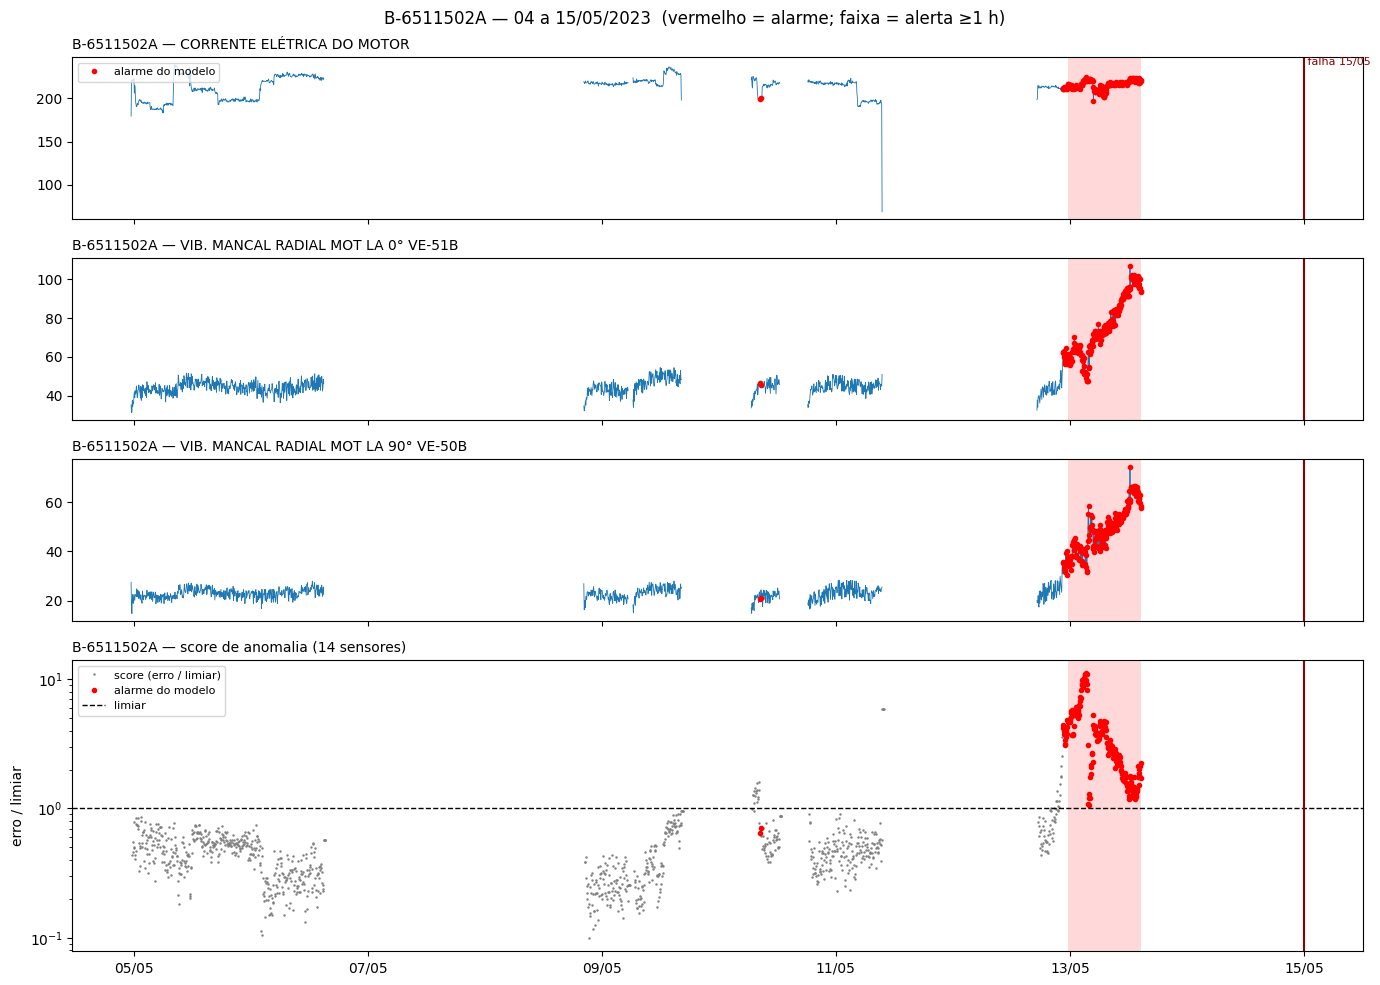

pontos em alarme: 201   pontos em alerta (≥1 h): 181


In [5]:
r1 = regras["regra B-8802B-2025 (15 de 20, alerta ≥1 h)"]
rel1 = r1["reconstruction_error"] / THR
SENS = ["CORRENTE ELÉTRICA DO MOTOR", "VIB. MANCAL RADIAL MOT LA 0° VE-51B", "VIB. MANCAL RADIAL MOT LA 90° VE-50B"]

def faixas(ax, flag):
    for a, b in episodios(flag):
        ax.axvspan(a, b + pd.Timedelta("5min"), color="red", alpha=0.15, lw=0)

for titulo, ini, fim in (("ano inteiro", None, None), ("04 a 15/05/2023", "2023-05-04", "2023-05-15 12:00")):
    fig, axs = plt.subplots(len(SENS) + 1, 1, figsize=(14, 10), sharex=True,
                            gridspec_kw={"height_ratios": [1] * len(SENS) + [1.8]})
    an = r1["is_anomaly"].loc[ini:fim]
    t_an = an.index[an]
    for ax, s in zip(axs, SENS):
        x = raw.loc[ini:fim, s].where(raw.loc[ini:fim, "CORRENTE ELÉTRICA DO MOTOR"] > 60)
        ax.plot(x.index, x, lw=0.6, color="tab:blue")
        ax.plot(t_an, raw[s].reindex(t_an), "o", ms=3, color="red", label="alarme do modelo")
        faixas(ax, r1["alerta"].loc[ini:fim])
        ax.set_title(f"{EQUIP} — {s}", fontsize=10, loc="left")
    axs[0].legend(loc="upper left", fontsize=8)
    ax = axs[-1]
    r = rel1.loc[ini:fim]
    ax.plot(r.index, r, ".", ms=1.5, color="gray", label="score (erro / limiar)")
    ax.plot(t_an, r.reindex(t_an), "o", ms=3, color="red", label="alarme do modelo")
    faixas(ax, r1["alerta"].loc[ini:fim])
    ax.axhline(1, color="k", ls="--", lw=1, label="limiar")
    ax.set_yscale("log"); ax.set_ylabel("erro / limiar")
    ax.set_title(f"{EQUIP} — score de anomalia (14 sensores)", fontsize=10, loc="left")
    ax.legend(loc="upper left", fontsize=8)
    for a in axs:
        a.axvline(FALHA, color="darkred", lw=1.5)
    axs[0].text(FALHA, axs[0].get_ylim()[1], " falha 15/05", color="darkred", va="top", fontsize=8)
    axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y" if ini is None else "%d/%m"))
    fig.suptitle(f"{EQUIP} — {titulo}  (vermelho = alarme; faixa = alerta ≥1 h)", fontsize=12)
    fig.tight_layout()
    plt.show()

print(f"pontos em alarme: {int(r1['is_anomaly'].sum())}   pontos em alerta (≥1 h): {int(r1['alerta'].sum())}")

## Resumo

**Modelo de anomalia, no ano de 2022–23:**

- **Bundle como está (alarme = alerta, 6 pontos seguidos):** 4 alertas.
  - 2 falsos e curtos no período normal: 24/06/2022 (10 min) e 22/07/2022 (45 min).
  - 1 curto em 10/05/2023 (25 min).
  - O contínuo começa em 12/05 às 22:10, cerca de **50 h antes** da falha, e segue até a bomba parar em 13/05 às 14:35.
- **Com a regra do B-8802B-2025 (15 de 20, alerta só com 1 h ou mais):** 1 alerta só, a partir de 12/05 às 23:35, cerca de **48 h antes** da falha.
  - Some com os 2 falsos e com o curto de 10/05.
  - Perde cerca de 1,5 h de antecedência.
- **11/05:** o erro passa de 5× o limiar, mas num ponto isolado, então nenhuma das duas regras alerta.
- **Início da subida:** já em 09/05 o erro sobe dentro da corrida (de 0,2 para 0,9 do limiar), mas sem passar dele.
- **Antecedência, com cuidado:**
  - os "48–50 h" são contados até a data registrada da falha (15/05);
  - a bomba parou em 13/05 às 14:35, cerca de 16 h depois do início do alerta, com a vibração do mancal LA do motor indo de ~40 para ~100;
  - não sabemos se essa parada já foi por causa do problema. Se foi, a antecedência real é de ~16 h.
  - É um detector de **fase tardia**: horas a ~2 dias, sem rampa longa.
- **Sinal:** quem carrega é a vibração radial do mancal LA do motor (VE-50B e VE-51B).

**O que falta para considerar pronto:**

1. **Rodar em dado de 2024–2026**, que ainda não temos. É o teste que importa: no B-8802B o modelo de 2022 deu 12% do tempo em alarme quando mudou o regime.
2. **Adotar a regra de 1 h no `alarm.json` deste bundle**, igual ao B-8802B-2025. Pelo resultado acima, ela limpa os falsos e custa pouco.
3. **Criar as referências do monitor de mudança de conceito** (KS e resíduo) para este equipamento.